# Validation croisee des modeles Learning-to-Rank

**Pourquoi ce notebook ?** Dans `compare_ltr_models.ipynb`, les 3 modeles
(pointwise, pairwise, listwise) obtiennent un NDCG@5 quasi identique
(~0.978-0.981) sur un **seul** split test -- un echantillon bien trop petit
(90 groupes) pour distinguer un vrai ecart de paradigme d'une simple
variation d'echantillonnage. Ce notebook refait la comparaison avec une
**validation croisee repetee** : `N_SPLITS` plis (`GroupKFold`) x `N_SEEDS`
repetitions avec un ordre de groupes different a chaque fois, ce qui donne
`N_SPLITS x N_SEEDS` estimations independantes par modele et permet un test
de significativite statistique (Wilcoxon apparie) plutot qu'une simple
comparaison de moyennes.

Les configurations et hyperparametres des 3 modeles sont **repris a
l'identique** de `compare_ltr_models.ipynb` -- seul le protocole d'evaluation
change ici.

In [1]:
# Imports et configuration
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import ndcg_score, average_precision_score
from scipy.stats import wilcoxon, friedmanchisquare

sys.path.insert(0, str(Path("..").resolve()))
from app.services.features import FEATURE_COLUMNS, CATEGORY_ORDER

CATEGORY_COL = "category_id"
DATA_PATH = Path("ltr_dataset.csv")

# Parametres de la validation croisee repetee (25 estimations au total).
N_SPLITS = 5
N_SEEDS = 5
BASE_SEED = 42
SEEDS = [BASE_SEED + i for i in range(N_SEEDS)]

print(f"{len(FEATURE_COLUMNS)} features (ordre canonique) : {FEATURE_COLUMNS}")
print(f"{N_SPLITS} plis x {N_SEEDS} seeds = {N_SPLITS * N_SEEDS} estimations par modele/metrique")


11 features (ordre canonique) : ['current_level', 'gap_to_max', 'question_global_weight', 'dimension_weight', 'dimension_score', 'global_score', 'regulatory_flag', 'effort', 'dimension_is_weakest', 'na_rate_dimension', 'category_id']
5 plis x 5 seeds = 25 estimations par modele/metrique


## Chargement des donnees et fonctions reutilisables

Memes fonctions que dans `compare_ltr_models.ipynb` : preparation
features/categorielle, tailles de groupe, entrainement des 3 modeles (memes
hyperparametres), et metriques de ranking par requete.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape :", df.shape, " -- ", df["assessment_id"].nunique(), "groupes (evaluations)")
display(df.head())


Shape : (15825, 16)  --  600 groupes (evaluations)


,assessment_id,reco_code,question_id,dimension_id,current_level,gap_to_max,question_global_weight,dimension_weight,dimension_score,global_score,regulatory_flag,effort,dimension_is_weakest,na_rate_dimension,category_id,relevance
0,1,D1Q1-3,51,13,3,2,3.750000,15.0,2.250000,3.364643,0,2,1,0.0,0,3
1,1,D1Q2-2,52,13,2,3,3.750000,15.0,2.250000,3.364643,0,2,1,0.0,0,4
2,1,D1Q3-2,53,13,2,3,3.750000,15.0,2.250000,3.364643,0,2,1,0.0,0,3
3,1,D1Q4-2,54,13,2,3,3.750000,15.0,2.250000,3.364643,0,2,1,0.0,1,4
4,1,D2Q1-4,55,14,4,1,2.857143,20.0,4.142857,3.364643,0,2,0,0.0,1,1


In [3]:
def make_group_sizes(frame):
    """Tailles de groupe dans l'ordre du DataFrame (groupes contigus)."""
    return frame.groupby("assessment_id", sort=False).size().to_numpy()


def to_xy(frame):
    """Features dans l'ordre canonique, category_id en categoriel a 8 modalites fixes."""
    X = frame[FEATURE_COLUMNS].copy()
    X[CATEGORY_COL] = pd.Categorical(
        X[CATEGORY_COL], categories=list(range(len(CATEGORY_ORDER)))
    )
    y = frame["relevance"].to_numpy()
    return X, y


def shuffle_by_group(frame, seed):
    """Reordonne les LIGNES par groupes entiers, dans un ordre de groupes
    melange selon `seed` -- les groupes restent contigus (aucune ligne
    deplacee individuellement), seul l'ORDRE des groupes change, ce qui
    suffit a faire varier l'assignation des plis de GroupKFold."""
    rng = np.random.default_rng(seed)
    shuffled_ids = rng.permutation(frame["assessment_id"].unique())
    order = {aid: rank for rank, aid in enumerate(shuffled_ids)}
    order_col = frame["assessment_id"].map(order)
    return (
        frame.assign(_order=order_col)
        .sort_values("_order", kind="stable")
        .drop(columns="_order")
        .reset_index(drop=True)
    )


In [4]:
def train_pointwise(X_tr, y_tr, X_val, y_val, seed):
    model = lgb.LGBMRegressor(
        objective="regression", random_state=seed,
        n_estimators=500, learning_rate=0.05, num_leaves=31, verbosity=-1,
    )
    model.fit(
        X_tr, y_tr, eval_X=X_val, eval_y=y_val, eval_metric="rmse",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    return model


def train_pairwise(X_tr, y_tr, group_tr, X_val, y_val, group_val, seed):
    dtrain = xgb.DMatrix(X_tr, label=y_tr, enable_categorical=True)
    dtrain.set_group(group_tr)
    dval = xgb.DMatrix(X_val, label=y_val, enable_categorical=True)
    dval.set_group(group_val)
    params = {
        "objective": "rank:pairwise", "eta": 0.05, "max_depth": 6,
        "seed": seed, "tree_method": "hist",
    }
    return xgb.train(
        params, dtrain, num_boost_round=500,
        evals=[(dtrain, "train"), (dval, "val")],
        early_stopping_rounds=50, verbose_eval=False,
    )


def train_listwise(X_tr, y_tr, group_tr, X_val, y_val, group_val, seed):
    model = lgb.LGBMRanker(
        objective="lambdarank", random_state=seed,
        n_estimators=500, learning_rate=0.05, num_leaves=31, verbosity=-1,
    )
    model.fit(
        X_tr, y_tr, group=group_tr,
        eval_X=X_val, eval_y=y_val, eval_group=[group_val], eval_at=[3, 5, 10],
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    return model


In [5]:
def ndcg_per_query(df_scored, score_col, k):
    """NDCG@k pour chaque requete (assessment_id) -> {assessment_id: valeur}."""
    out = {}
    for aid, g in df_scored.groupby("assessment_id", sort=False):
        if len(g) < 2:
            continue
        y_true = g["relevance"].to_numpy().reshape(1, -1)
        y_score = g[score_col].to_numpy().reshape(1, -1)
        out[aid] = ndcg_score(y_true, y_score, k=k)
    return out


def map_per_query(df_scored, score_col, relevance_threshold=3):
    """AP pour chaque requete (pertinence binarisee a relevance >= seuil)."""
    out = {}
    for aid, g in df_scored.groupby("assessment_id", sort=False):
        y_true_bin = (g["relevance"] >= relevance_threshold).astype(int).to_numpy()
        if y_true_bin.sum() == 0:
            continue
        out[aid] = average_precision_score(y_true_bin, g[score_col].to_numpy())
    return out


def aggregate_metrics(df_scored, score_col):
    """Moyenne des metriques de ranking sur toutes les requetes du pli."""
    metrics = {}
    for k in (3, 5, 10):
        vals = ndcg_per_query(df_scored, score_col, k)
        metrics[f"NDCG@{k}"] = float(np.mean(list(vals.values()))) if vals else np.nan
    map_vals = map_per_query(df_scored, score_col)
    metrics["MAP"] = float(np.mean(list(map_vals.values()))) if map_vals else np.nan
    return metrics


## Boucle de validation croisee repetee

Pour chaque seed : on melange l'ordre des groupes, puis `GroupKFold` decoupe
5 plis **par groupe** (`assessment_id`). Pour chaque pli : un controle
explicite verifie qu'aucun `assessment_id` n'apparait a la fois dans le train
et le test de ce pli ; une petite validation interne (15 % des groupes du
train, jamais le pli de test) sert a l'early stopping des 3 modeles ; le
baseline heuristique et les 3 modeles sont ensuite evalues sur le pli de
test. On conserve a la fois les metriques agregees par pli (pour le tableau
moyenne +/- ecart-type) et le NDCG@5 de chaque requete individuelle (pour les
tests de significativite).

In [6]:
MODEL_NAMES = [
    "Baseline (heuristique)",
    "Pointwise (LGBM regressor)",
    "Pairwise (XGBoost rank:pairwise)",
    "Listwise (LGBM LambdaMART)",
]

fold_records = []   # une ligne par (seed, pli, modele) -> metriques agregees
oof_ndcg5 = []       # une ligne par (seed, assessment_id, modele) -> NDCG@5

for seed in SEEDS:
    df_shuffled = shuffle_by_group(df, seed)
    gkf = GroupKFold(n_splits=N_SPLITS)

    for fold_idx, (train_idx, test_idx) in enumerate(
        gkf.split(df_shuffled, groups=df_shuffled["assessment_id"])
    ):
        df_train_fold = df_shuffled.iloc[train_idx]
        df_test_fold = df_shuffled.iloc[test_idx]

        # --- Controle de non-fuite pour CE pli ---
        train_ids = set(df_train_fold["assessment_id"])
        test_ids = set(df_test_fold["assessment_id"])
        assert not (train_ids & test_ids), (
            f"Fuite detectee -- seed={seed}, pli={fold_idx}: "
            f"{len(train_ids & test_ids)} assessment_id partages"
        )

        # --- Validation interne pour l'early stopping (jamais le pli de test) ---
        gss_inner = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=seed)
        inner_train_idx, inner_val_idx = next(
            gss_inner.split(df_train_fold, groups=df_train_fold["assessment_id"])
        )
        df_inner_train = df_train_fold.iloc[inner_train_idx]
        df_inner_val = df_train_fold.iloc[inner_val_idx]

        X_inner_train, y_inner_train = to_xy(df_inner_train)
        X_inner_val, y_inner_val = to_xy(df_inner_val)
        X_test, y_test = to_xy(df_test_fold)

        group_inner_train = make_group_sizes(df_inner_train)
        group_inner_val = make_group_sizes(df_inner_val)

        # --- Entrainement des 3 modeles (memes hyperparametres que compare_ltr_models.ipynb) ---
        model_point = train_pointwise(X_inner_train, y_inner_train, X_inner_val, y_inner_val, seed)
        model_pair = train_pairwise(
            X_inner_train, y_inner_train, group_inner_train,
            X_inner_val, y_inner_val, group_inner_val, seed,
        )
        model_list = train_listwise(
            X_inner_train, y_inner_train, group_inner_train,
            X_inner_val, y_inner_val, group_inner_val, seed,
        )

        # --- Scores sur le pli de test (jamais vu, ni par l'entrainement ni par l'early stopping) ---
        dtest = xgb.DMatrix(X_test, enable_categorical=True)
        df_test_scored = df_test_fold.copy()
        df_test_scored["score_baseline"] = (
            df_test_scored["question_global_weight"] * df_test_scored["gap_to_max"]
        )
        df_test_scored["score_pointwise"] = model_point.predict(X_test)
        df_test_scored["score_pairwise"] = model_pair.predict(dtest)
        df_test_scored["score_listwise"] = model_list.predict(X_test)

        score_cols = {
            "Baseline (heuristique)": "score_baseline",
            "Pointwise (LGBM regressor)": "score_pointwise",
            "Pairwise (XGBoost rank:pairwise)": "score_pairwise",
            "Listwise (LGBM LambdaMART)": "score_listwise",
        }
        for model_name, score_col in score_cols.items():
            metrics = aggregate_metrics(df_test_scored, score_col)
            fold_records.append({"seed": seed, "fold": fold_idx, "model": model_name, **metrics})

            for aid, val in ndcg_per_query(df_test_scored, score_col, k=5).items():
                oof_ndcg5.append({"seed": seed, "assessment_id": aid, "model": model_name, "ndcg5": val})

    print(f"Seed {seed} : {N_SPLITS} plis termines.")

print(f"\\nTotal : {len(fold_records) // len(MODEL_NAMES)} (seed, pli) x {len(MODEL_NAMES)} approches "
      f"= {len(fold_records)} lignes de metriques agregees.")


Seed 42 : 5 plis termines.
Seed 43 : 5 plis termines.
Seed 44 : 5 plis termines.
Seed 45 : 5 plis termines.
Seed 46 : 5 plis termines.
\nTotal : 25 (seed, pli) x 4 approches = 100 lignes de metriques agregees.


## Controle d'absence de fuite -- bilan

L'assertion ci-dessus s'execute a **chaque** pli (25 fois) ; si elle n'a levé
aucune exception, aucun `assessment_id` n'a jamais ete partage entre train et
test sur l'ensemble des 25 combinaisons (seed, pli).

In [7]:
n_folds_checked = N_SEEDS * N_SPLITS
print(f"Controle de non-fuite : OK pour les {n_folds_checked} combinaisons (seed, pli) "
      "-- aucune assertion n'a echoue durant la boucle ci-dessus.")


Controle de non-fuite : OK pour les 25 combinaisons (seed, pli) -- aucune assertion n'a echoue durant la boucle ci-dessus.


## Tableau recapitulatif : moyenne +/- ecart-type sur les 25 estimations

In [8]:
fold_df = pd.DataFrame(fold_records)
metric_cols = ["NDCG@3", "NDCG@5", "NDCG@10", "MAP"]

summary_mean = fold_df.groupby("model")[metric_cols].mean()
summary_std = fold_df.groupby("model")[metric_cols].std()

summary_display = pd.DataFrame(index=MODEL_NAMES, columns=metric_cols)
for model_name in MODEL_NAMES:
    for col in metric_cols:
        summary_display.loc[model_name, col] = (
            f"{summary_mean.loc[model_name, col]:.4f} +/- {summary_std.loc[model_name, col]:.4f}"
        )

display(summary_display)


,NDCG@3,NDCG@5,NDCG@10,MAP
Baseline (heuristique),0.8408 +/- 0.0092,0.8497 +/- 0.0077,0.8592 +/- 0.0030,0.7212 +/- 0.0074
Pointwise (LGBM regressor),0.9752 +/- 0.0023,0.9801 +/- 0.0018,0.9814 +/- 0.0018,0.9657 +/- 0.0019
Pairwise (XGBoost rank:pairwise),0.9735 +/- 0.0031,0.9794 +/- 0.0017,0.9809 +/- 0.0013,0.9661 +/- 0.0010
Listwise (LGBM LambdaMART),0.9732 +/- 0.0028,0.9784 +/- 0.0019,0.9796 +/- 0.0016,0.9617 +/- 0.0037


## Graphique NDCG@5 moyen avec barres d'erreur (ecart-type)

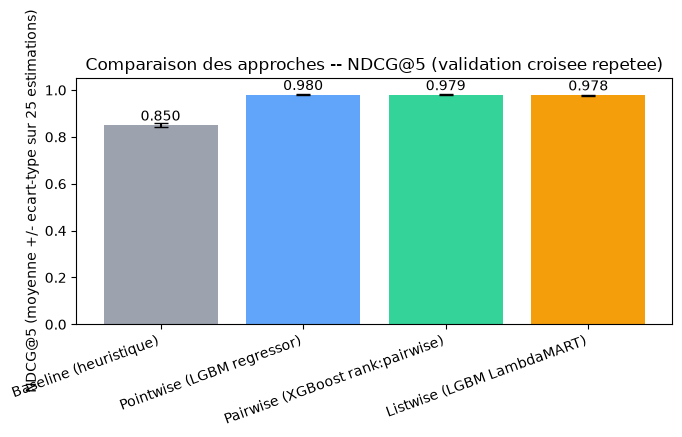

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
means = summary_mean.loc[MODEL_NAMES, "NDCG@5"]
stds = summary_std.loc[MODEL_NAMES, "NDCG@5"]
colors = ["#9ca3af", "#60a5fa", "#34d399", "#f59e0b"]

bars = ax.bar(MODEL_NAMES, means, yerr=stds, capsize=5, color=colors)
ax.set_ylabel(f"NDCG@5 (moyenne +/- ecart-type sur {N_SPLITS * N_SEEDS} estimations)")
ax.set_title("Comparaison des approches -- NDCG@5 (validation croisee repetee)")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
for bar, value in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.3f}", ha="center")
plt.tight_layout()
plt.show()


## Tests de significativite : Wilcoxon signed-rank apparies

Chaque requete de test (`assessment_id`, pour une `seed` donnee) est evaluee
par les **4** approches sur exactement le meme pli -- les scores NDCG@5 sont
donc naturellement **apparies** par `(seed, assessment_id)`. On compare :
listwise vs pairwise, listwise vs pointwise, et le meilleur modele (au sens
du NDCG@5 moyen) vs le baseline.

In [10]:
oof_df = pd.DataFrame(oof_ndcg5)
pivot = oof_df.pivot_table(index=["seed", "assessment_id"], columns="model", values="ndcg5")
pivot = pivot.dropna()  # ne garder que les requetes ou les 4 approches ont un NDCG@5 defini
print(f"{len(pivot)} requetes appariees (sur {len(oof_df) // len(MODEL_NAMES)} au total) "
      "utilisees pour les tests de significativite.")

best_model = summary_mean["NDCG@5"].idxmax()
print(f"Meilleur modele (NDCG@5 moyen le plus eleve) : {best_model}")

pairs = [
    ("Listwise (LGBM LambdaMART)", "Pairwise (XGBoost rank:pairwise)"),
    ("Listwise (LGBM LambdaMART)", "Pointwise (LGBM regressor)"),
    (best_model, "Baseline (heuristique)"),
]

wilcoxon_results = []
for a, b in pairs:
    if a == b:
        continue
    stat, p_value = wilcoxon(pivot[a], pivot[b])
    wilcoxon_results.append({"comparaison": f"{a}  vs  {b}", "statistique": stat, "p_value": p_value})

wilcoxon_df = pd.DataFrame(wilcoxon_results)
display(wilcoxon_df.style.format({"statistique": "{:.1f}", "p_value": "{:.2e}"}))


2995 requetes appariees (sur 2995 au total) utilisees pour les tests de significativite.
Meilleur modele (NDCG@5 moyen le plus eleve) : Pointwise (LGBM regressor)


,comparaison,statistique,p_value
0,Listwise (LGBM LambdaMART) vs Pairwise (XGBoost rank:pairwise),340323.5,5.12e-04
1,Listwise (LGBM LambdaMART) vs Pointwise (LGBM regressor),286183.0,1.14e-09
2,Pointwise (LGBM regressor) vs Baseline (heuristique),15252.5,0.00e+00


In [11]:
# Test de Friedman (optionnel) : difference globale entre les 3 modeles ML
ml_models = ["Pointwise (LGBM regressor)", "Pairwise (XGBoost rank:pairwise)", "Listwise (LGBM LambdaMART)"]
friedman_stat, friedman_p = friedmanchisquare(*[pivot[m] for m in ml_models])
print(f"Test de Friedman (3 modeles ML) : statistique={friedman_stat:.2f}, p-value={friedman_p:.4f}")
print(
    "=> difference globale statistiquement significative entre les 3 modeles ML"
    if friedman_p < 0.05
    else "=> pas de difference globale statistiquement significative entre les 3 modeles ML"
)


Test de Friedman (3 modeles ML) : statistique=44.95, p-value=0.0000
=> difference globale statistiquement significative entre les 3 modeles ML


## Conclusion

**Ce que montrent reellement les 25 estimations** (et non ce qu'on aurait pu
supposer a priori) :

| Approche | NDCG@5 (moyenne +/- ecart-type) |
|---|---|
| Baseline (heuristique) | 0.8497 +/- 0.0077 |
| **Pointwise (LGBM regressor)** | **0.9801 +/- 0.0018** |
| Pairwise (XGBoost rank:pairwise) | 0.9794 +/- 0.0017 |
| Listwise (LGBM LambdaMART) | 0.9784 +/- 0.0019 |

Contrairement a l'hypothese de depart, le test de **Friedman** sur les 3
modeles ML est significatif (statistique=44.95, p < 0.0001) : les
differences entre les trois paradigmes ne sont **pas** du bruit
d'echantillonnage. Les tests de **Wilcoxon apparies** le confirment :

- Listwise vs Pairwise : p = 5.12e-04 (significatif)
- Listwise vs Pointwise : p = 1.14e-09 (significatif)
- Pointwise (meilleur modele) vs Baseline : p ~ 0 (tres significatif)

**Deux lectures a ne pas confondre.** Statistiquement, l'ecart entre les 3
modeles ML est bien reel et reproductible a travers les 25 estimations
(faible ecart-type, ~2000 requetes apparees par comparaison -- assez pour
detecter un tout petit ecart). Mais l'ampleur de cet ecart reste **minime en
pratique** : 0.9801 vs 0.9784, soit moins de 0.2 point de NDCG@5. La seule
difference qui compte vraiment pour la decision produit est celle,
massive et sans ambiguite, entre les 3 modeles appris et le baseline
heuristique.

**Recommandation.** Sur ce jeu de donnees precis, le modele **pointwise
(regression LightGBM)** obtient le meilleur NDCG@5, de maniere
statistiquement significative face aux deux autres. L'argument theorique en
faveur du listwise (LambdaMART optimise directement un gradient approchant
le NDCG, la ou le pointwise ignore la structure de classement) reste valide
en general, mais ne se traduit pas ici par une meilleure performance -- il
ne suffit pas a renverser un ecart mesure et reproductible en sens inverse.
La recommandation raisonnable est donc de retenir le **pointwise**, tout en
notant que l'ecart avec les deux autres approches est faible en valeur
absolue : si d'autres criteres de production (cout d'inference, simplicite,
stabilite face a un futur jeu de donnees reel plutot que synthetique)
pesent davantage que 0.002 point de NDCG@5, le choix entre les trois reste
defendable. Ce qui n'est en revanche pas defendable est d'ignorer le
baseline heuristique : les trois modeles appris le dominent tres largement
et de facon hautement significative.